<a href="https://colab.research.google.com/github/sengercoding/CVfinal/blob/main/CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install datasets

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 485.4/485.4 kB 16.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 116.3/116.3 kB 8.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 143.5/143.5 kB 13.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 194.8/194.8 kB 9.8 MB/s eta 0:00:00


In [2]:
from datasets import load_dataset
import numpy as np
import cv2
import torch
from torchvision import transforms
from PIL import Image
import matplotlib.pyplot as plt


# Load the dataset
dataset = load_dataset("biglam/dating-historical-color-images")

# Function to preprocess images (convert to grayscale for input)
import numpy as np
import cv2
import torch

def preprocess_image(example):
    img = np.array(example['image'])  # Convert to NumPy array
    img = cv2.cvtColor(img, cv2.COLOR_RGB2LAB)  # Convert to LAB
    img = cv2.resize(img, (256, 256))  # Resize to fixed size

    ''' L = img[:, :, 0]  # Extract L channel
    AB = img[:, :, 1:]  # Extract AB channels '''
    L, A, B = cv2.split(img)  # Separate LAB channels

    # Normalize L to [0,1] and AB to [-1,1]
    L = L / 255.0  # Normalize L to [0,1]
    A = (A - 128) / 128.0  # Normalize A to [-1,1]
    B = (B - 128) / 128.0  # Normalize B to [-1,1]

    AB = np.stack([A, B], axis=-1)  # Stack AB channels


    # Convert to PyTorch tensors
    L = torch.tensor(L).unsqueeze(0)  # Shape: (1, 224, 224)
    AB = torch.tensor(AB).permute(2, 0, 1)  # Shape: (2, 224, 224)
    return {'L': L, 'AB': AB}  # Return input (L) and label (AB)

# Apply preprocessing to the dataset
dataset = dataset.map(preprocess_image)

/usr/local/lib/python3.11/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md:   0%|          | 0.00/4.79k [00:00<?, ?B/s]

dating-historical-color-images.py:   0%|          | 0.00/3.76k [00:00<?, ?B/s]

0000.parquet:   0%|          | 0.00/221M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/1325 [00:00<?, ? examples/s]

Map:   0%|          | 0/1325 [00:00<?, ? examples/s]

In [3]:
import torch
import torch.nn as nn
import torch.optim as optim

class ColorizationCNN(nn.Module):
    def __init__(self):
        super(ColorizationCNN, self).__init__()

        # Encoder (Feature Extraction)
        self.encoder = nn.Sequential(
            nn.Conv2d(1, 64, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.Conv2d(64, 128, kernel_size=3, stride=2, padding=1),
            nn.ReLU(),
            nn.Conv2d(128, 256, kernel_size=3, stride=2, padding=1),
            nn.ReLU()
        )

        # Decoder (Upsampling to AB channels)
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(256, 128, kernel_size=3, stride=2, padding=1, output_padding=1),
            nn.ReLU(),
            nn.ConvTranspose2d(128, 64, kernel_size=3, stride=2, padding=1, output_padding=1),
            nn.ReLU(),
            nn.Conv2d(64, 2, kernel_size=3, stride=1, padding=1),
            nn.Tanh()  # Output AB in range [-1,1]
        )

    def forward(self, x):
        x = self.encoder(x)
        x = self.decoder(x)
        return x  # Output shape: (2, 224, 224) - predicted AB channels


In [4]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class AlexNetColorization(nn.Module):
    def __init__(self):
        super(AlexNetColorization, self).__init__()

        # Feature Extractor (same as standard AlexNet)
        self.features = nn.Sequential(
            nn.Conv2d(1, 64, kernel_size=11, stride=4, padding=2),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=3, stride=2),

            nn.Conv2d(64, 192, kernel_size=5, padding=2),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=3, stride=2),

            nn.Conv2d(192, 384, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),

            nn.Conv2d(384, 256, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),

            nn.Conv2d(256, 256, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=3, stride=2)
        )

        # Decoder (upsampling AB channels) - Modified to output 256x256
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(256, 128, kernel_size=3, stride=2, padding=1, output_padding=1),
            nn.ReLU(inplace=True),

            nn.ConvTranspose2d(128, 64, kernel_size=3, stride=2, padding=1, output_padding=1),
            nn.ReLU(inplace=True),

            # Modified Upsampling layer with scale_factor=4
            nn.Upsample(scale_factor=4, mode='bilinear', align_corners=False),

            nn.Conv2d(64, 2, kernel_size=3, padding=1),  # 2 Output Channels (AB)
            nn.Tanh()  # Output AB values in range [-1,1]
        )

    def forward(self, x):
        x = self.features(x)  # Extract features
        x = self.decoder(x)   # Generate AB channels
        return x  # Output AB (2, 224, 224)

In [5]:
from torch import nn

class BaseColor(nn.Module):
	def __init__(self):
		super(BaseColor, self).__init__()

		self.l_cent = 50.
		self.l_norm = 100.
		self.ab_norm = 110.

	def normalize_l(self, in_l):
		return (in_l-self.l_cent)/self.l_norm

	def unnormalize_l(self, in_l):
		return in_l*self.l_norm + self.l_cent

	def normalize_ab(self, in_ab):
		return in_ab/self.ab_norm

	def unnormalize_ab(self, in_ab):
		return in_ab*self.ab_norm

class ECCVGenerator(BaseColor):
    def __init__(self, norm_layer=nn.BatchNorm2d):
        super(ECCVGenerator, self).__init__()

        model1=[nn.Conv2d(1, 64, kernel_size=3, stride=1, padding=1, bias=True),]
        model1+=[nn.ReLU(True),]
        model1+=[nn.Conv2d(64, 64, kernel_size=3, stride=2, padding=1, bias=True),]
        model1+=[nn.ReLU(True),]
        model1+=[norm_layer(64),]

        model2=[nn.Conv2d(64, 128, kernel_size=3, stride=1, padding=1, bias=True),]
        model2+=[nn.ReLU(True),]
        model2+=[nn.Conv2d(128, 128, kernel_size=3, stride=2, padding=1, bias=True),]
        model2+=[nn.ReLU(True),]
        model2+=[norm_layer(128),]

        model3=[nn.Conv2d(128, 256, kernel_size=3, stride=1, padding=1, bias=True),]
        model3+=[nn.ReLU(True),]
        model3+=[nn.Conv2d(256, 256, kernel_size=3, stride=1, padding=1, bias=True),]
        model3+=[nn.ReLU(True),]
        model3+=[nn.Conv2d(256, 256, kernel_size=3, stride=2, padding=1, bias=True),]
        model3+=[nn.ReLU(True),]
        model3+=[norm_layer(256),]

        model4=[nn.Conv2d(256, 512, kernel_size=3, stride=1, padding=1, bias=True),]
        model4+=[nn.ReLU(True),]
        model4+=[nn.Conv2d(512, 512, kernel_size=3, stride=1, padding=1, bias=True),]
        model4+=[nn.ReLU(True),]
        model4+=[nn.Conv2d(512, 512, kernel_size=3, stride=1, padding=1, bias=True),]
        model4+=[nn.ReLU(True),]
        model4+=[norm_layer(512),]

        model5=[nn.Conv2d(512, 512, kernel_size=3, dilation=2, stride=1, padding=2, bias=True),]
        model5+=[nn.ReLU(True),]
        model5+=[nn.Conv2d(512, 512, kernel_size=3, dilation=2, stride=1, padding=2, bias=True),]
        model5+=[nn.ReLU(True),]
        model5+=[nn.Conv2d(512, 512, kernel_size=3, dilation=2, stride=1, padding=2, bias=True),]
        model5+=[nn.ReLU(True),]
        model5+=[norm_layer(512),]

        model6=[nn.Conv2d(512, 512, kernel_size=3, dilation=2, stride=1, padding=2, bias=True),]
        model6+=[nn.ReLU(True),]
        model6+=[nn.Conv2d(512, 512, kernel_size=3, dilation=2, stride=1, padding=2, bias=True),]
        model6+=[nn.ReLU(True),]
        model6+=[nn.Conv2d(512, 512, kernel_size=3, dilation=2, stride=1, padding=2, bias=True),]
        model6+=[nn.ReLU(True),]
        model6+=[norm_layer(512),]

        model7=[nn.Conv2d(512, 512, kernel_size=3, stride=1, padding=1, bias=True),]
        model7+=[nn.ReLU(True),]
        model7+=[nn.Conv2d(512, 512, kernel_size=3, stride=1, padding=1, bias=True),]
        model7+=[nn.ReLU(True),]
        model7+=[nn.Conv2d(512, 512, kernel_size=3, stride=1, padding=1, bias=True),]
        model7+=[nn.ReLU(True),]
        model7+=[norm_layer(512),]

        model8=[nn.ConvTranspose2d(512, 256, kernel_size=4, stride=2, padding=1, bias=True),]
        model8+=[nn.ReLU(True),]
        model8+=[nn.Conv2d(256, 256, kernel_size=3, stride=1, padding=1, bias=True),]
        model8+=[nn.ReLU(True),]
        model8+=[nn.Conv2d(256, 256, kernel_size=3, stride=1, padding=1, bias=True),]
        model8+=[nn.ReLU(True),]

        model8+=[nn.Conv2d(256, 313, kernel_size=1, stride=1, padding=0, bias=True),]

        self.model1 = nn.Sequential(*model1)
        self.model2 = nn.Sequential(*model2)
        self.model3 = nn.Sequential(*model3)
        self.model4 = nn.Sequential(*model4)
        self.model5 = nn.Sequential(*model5)
        self.model6 = nn.Sequential(*model6)
        self.model7 = nn.Sequential(*model7)
        self.model8 = nn.Sequential(*model8)

        self.softmax = nn.Softmax(dim=1)
        self.model_out = nn.Conv2d(313, 2, kernel_size=1, padding=0, dilation=1, stride=1, bias=False)
        self.upsample4 = nn.Upsample(scale_factor=4, mode='bilinear')

    def forward(self, input_l):
        conv1_2 = self.model1(self.normalize_l(input_l))
        conv2_2 = self.model2(conv1_2)
        conv3_3 = self.model3(conv2_2)
        conv4_3 = self.model4(conv3_3)
        conv5_3 = self.model5(conv4_3)
        conv8_3 = self.model8(conv4_3)

        out_reg = self.model_out(self.softmax(conv2_2))

        return self.unnormalize_ab(self.upsample4(out_reg))

'''         conv3_3 = self.model3(conv2_2)
        conv4_3 = self.model4(conv3_3)
        conv5_3 = self.model5(conv4_3)
        conv6_3 = self.model6(conv5_3)
        conv7_3 = self.model7(conv6_3)
        conv8_3 = self.model8(conv7_3) '''

'         conv3_3 = self.model3(conv2_2)\n        conv4_3 = self.model4(conv3_3)\n        conv5_3 = self.model5(conv4_3)\n        conv6_3 = self.model6(conv5_3)\n        conv7_3 = self.model7(conv6_3)\n        conv8_3 = self.model8(conv7_3) '

In [6]:
import torch
import torch.nn as nn

class SmallECCVGenerator(nn.Module):
    def __init__(self):
        super(SmallECCVGenerator, self).__init__()

        self.l_cent = 50.
        self.l_norm = 100.
        self.ab_norm = 110.

        def conv_layer(in_channels, out_channels, kernel_size=3, stride=1, padding=1):
            return nn.Sequential(
                nn.Conv2d(in_channels, out_channels, kernel_size, stride, padding, bias=False),
                nn.BatchNorm2d(out_channels),
                nn.ReLU(inplace=True)
            )

        self.encoder = nn.Sequential(
            conv_layer(1, 32, 3, 1, 1),  # Reduced from 64 to 32
            conv_layer(32, 64, 3, 2, 1),  # Downsample
            conv_layer(64, 128, 3, 2, 1),  # Downsample
            conv_layer(128, 256, 3, 2, 1),  # Downsample
        )

        self.middle = nn.Sequential(
            conv_layer(256, 256, 3, 1, 1),
            conv_layer(256, 256, 3, 1, 1),
        )

        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(256, 128, kernel_size=4, stride=2, padding=1),  # Upsample
            nn.ReLU(inplace=True),
            nn.ConvTranspose2d(128, 64, kernel_size=4, stride=2, padding=1),  # Upsample
            nn.ReLU(inplace=True),
            nn.ConvTranspose2d(64, 32, kernel_size=4, stride=2, padding=1),  # Upsample
            nn.ReLU(inplace=True),
            nn.Conv2d(32, 2, kernel_size=1, stride=1, padding=0),  # Output AB channels
        )

    def forward(self, input_l):
        x = self.encoder(self.normalize_l(input_l))
        x = self.middle(x)
        x = self.decoder(x)
        return self.unnormalize_ab(x)

    def normalize_l(self, in_l):
        return (in_l - self.l_cent) / self.l_norm

    def unnormalize_ab(self, in_ab):
        return in_ab * self.ab_norm


In [7]:
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from sklearn.model_selection import train_test_split

print(dataset["train"][0])
# Extract L channel from dataset["train"]
X = np.array([entry["L"] for entry in dataset["train"]])
Y = np.array([entry["AB"] for entry in dataset["train"]])
print(X.shape, Y.shape)

# Check shape
class ColorizationDataset(Dataset):
    def __init__(self, X, Y):
        self.X = X
        self.Y = Y

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.Y[idx]  # (L channel, AB channels)

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42, shuffle=True)
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)  # channel dim: (N, 1, H, W)
Y_train_tensor = torch.tensor(Y_train, dtype=torch.float32)  # Already (N, 2, H, W)

X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
Y_test_tensor = torch.tensor(Y_test, dtype=torch.float32)

train_dataset = ColorizationDataset(X_train_tensor, Y_train_tensor)
test_dataset = ColorizationDataset(X_test_tensor, Y_test_tensor)


batch_size = 16  # Adjust based on memory
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

{'image': <PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=500x333 at 0x7D5AE0DBFF50>, 'label': 4, 'L': [[[0.8980392156862745, 0.9098039215686274, 0.9137254901960784, 0.9254901960784314, 0.9294117647058824, 0.9254901960784314, 0.9411764705882353, 0.9490196078431372, 0.9490196078431372, 0.9607843137254902, 0.9647058823529412, 0.9725490196078431, 0.9686274509803922, 0.9764705882352941, 0.9764705882352941, 0.9803921568627451, 0.9882352941176471, 0.984313725490196, 0.984313725490196, 0.984313725490196, 0.9882352941176471, 0.9882352941176471, 0.9921568627450981, 0.9882352941176471, 0.9921568627450981, 0.996078431372549, 0.9921568627450981, 0.9921568627450981, 0.996078431372549, 0.996078431372549, 0.9921568627450981, 1.0, 1.0, 1.0, 1.0, 0.9921568627450981, 0.996078431372549, 0.996078431372549, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 0.996078431372549, 0.996078431372549, 1.0, 1.0, 0.996078431372549, 1.0, 0.9921568627450981, 0.9921568627450981, 0.7764705882352941, 0.796078431372549, 0.364705882352

In [8]:
import torch
import torch.optim as optim
import torch.nn as nn
import matplotlib.pyplot as plt
from tqdm import tqdm  # Progress bar
from torch.utils.tensorboard import SummaryWriter

# Model, Loss, Optimizer
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = SmallECCVGenerator().to(device)
alex_model = AlexNetColorization().to(device)
criterion = nn.MSELoss()  # Mean Squared Error for AB predictions
optimizer = optim.Adam(model.parameters(), lr=0.001)

# TensorBoard writer
writer = SummaryWriter()

# Training Parameters
num_epochs = 100
train_losses = []
test_losses = []

# Training Loop
for epoch in range(num_epochs):
    model.train()
    total_train_loss = 0

    train_bar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{num_epochs}", leave=False)  # Progress bar

    for L, AB in train_bar:
        L, AB = L.to(device), AB.to(device)

        optimizer.zero_grad()
        AB_pred = model(L)
        loss = criterion(AB_pred, AB)
        loss.backward()
        optimizer.step()

        total_train_loss += loss.item()
        train_bar.set_postfix(loss=loss.item())  # Show live loss update

    avg_train_loss = total_train_loss / len(train_loader)
    train_losses.append(avg_train_loss)
    writer.add_scalar("Loss/Train", avg_train_loss, epoch)  # Log to TensorBoard

    # Evaluate on test set
    model.eval()
    total_test_loss = 0

    with torch.no_grad():
        test_bar = tqdm(test_loader, desc="Testing", leave=False)
        for L, AB in test_bar:
            L, AB = L.to(device), AB.to(device)
            AB_pred = model(L)
            loss = criterion(AB_pred, AB)
            total_test_loss += loss.item()

    avg_test_loss = total_test_loss / len(test_loader)
    test_losses.append(avg_test_loss)
    writer.add_scalar("Loss/Test", avg_test_loss, epoch)  # Log to TensorBoard

    print(f"Epoch [{epoch+1}/{num_epochs}] - Train Loss: {avg_train_loss:.4f}, Test Loss: {avg_test_loss:.4f}")

writer.close()  # Close TensorBoard writer

Epoch [1/100] - Train Loss: 6.9296, Test Loss: 5.3810


Epoch [2/100] - Train Loss: 0.9449, Test Loss: 0.9239


Epoch [3/100] - Train Loss: 1.0141, Test Loss: 0.9875


Epoch [4/100] - Train Loss: 0.9151, Test Loss: 1.1261


Epoch [5/100] - Train Loss: 0.9768, Test Loss: 1.0137


Epoch [6/100] - Train Loss: 0.9664, Test Loss: 0.9544


... (90 outputs left out)

Epoch [97/100] - Train Loss: 0.7778, Test Loss: 2.0758


Epoch [98/100] - Train Loss: 0.7722, Test Loss: 40.1667


Epoch [99/100] - Train Loss: 0.7677, Test Loss: 12.5625


Epoch [100/100] - Train Loss: 0.7611, Test Loss: 1.5788


In [11]:
from google.colab import drive, files

drive.mount('/content/drive')

model_path = "/content/drive/MyDrive/colorization_model-small-eccv-100e.pth"
torch.save(model.state_dict(), model_path)
files.download(model_path)

Mounted at /content/drive


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

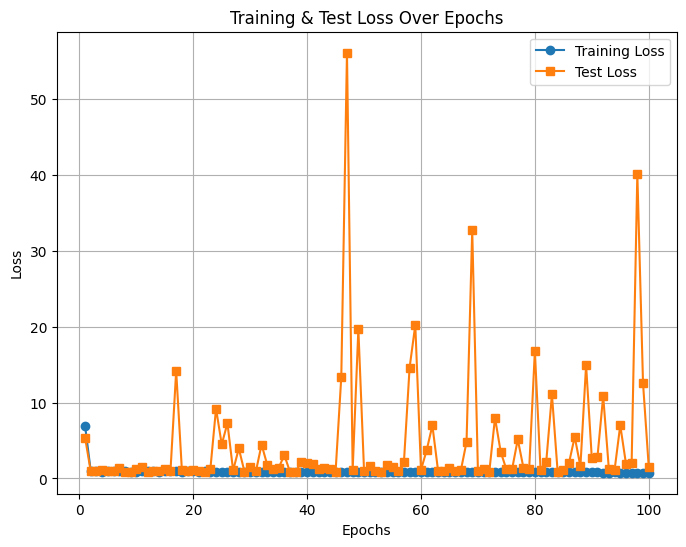

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
plt.plot(range(1, num_epochs + 1), train_losses, label="Training Loss", marker='o')
plt.plot(range(1, num_epochs + 1), test_losses, label="Test Loss", marker='s')
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Training & Test Loss Over Epochs")
plt.legend()
plt.grid()
plt.show()


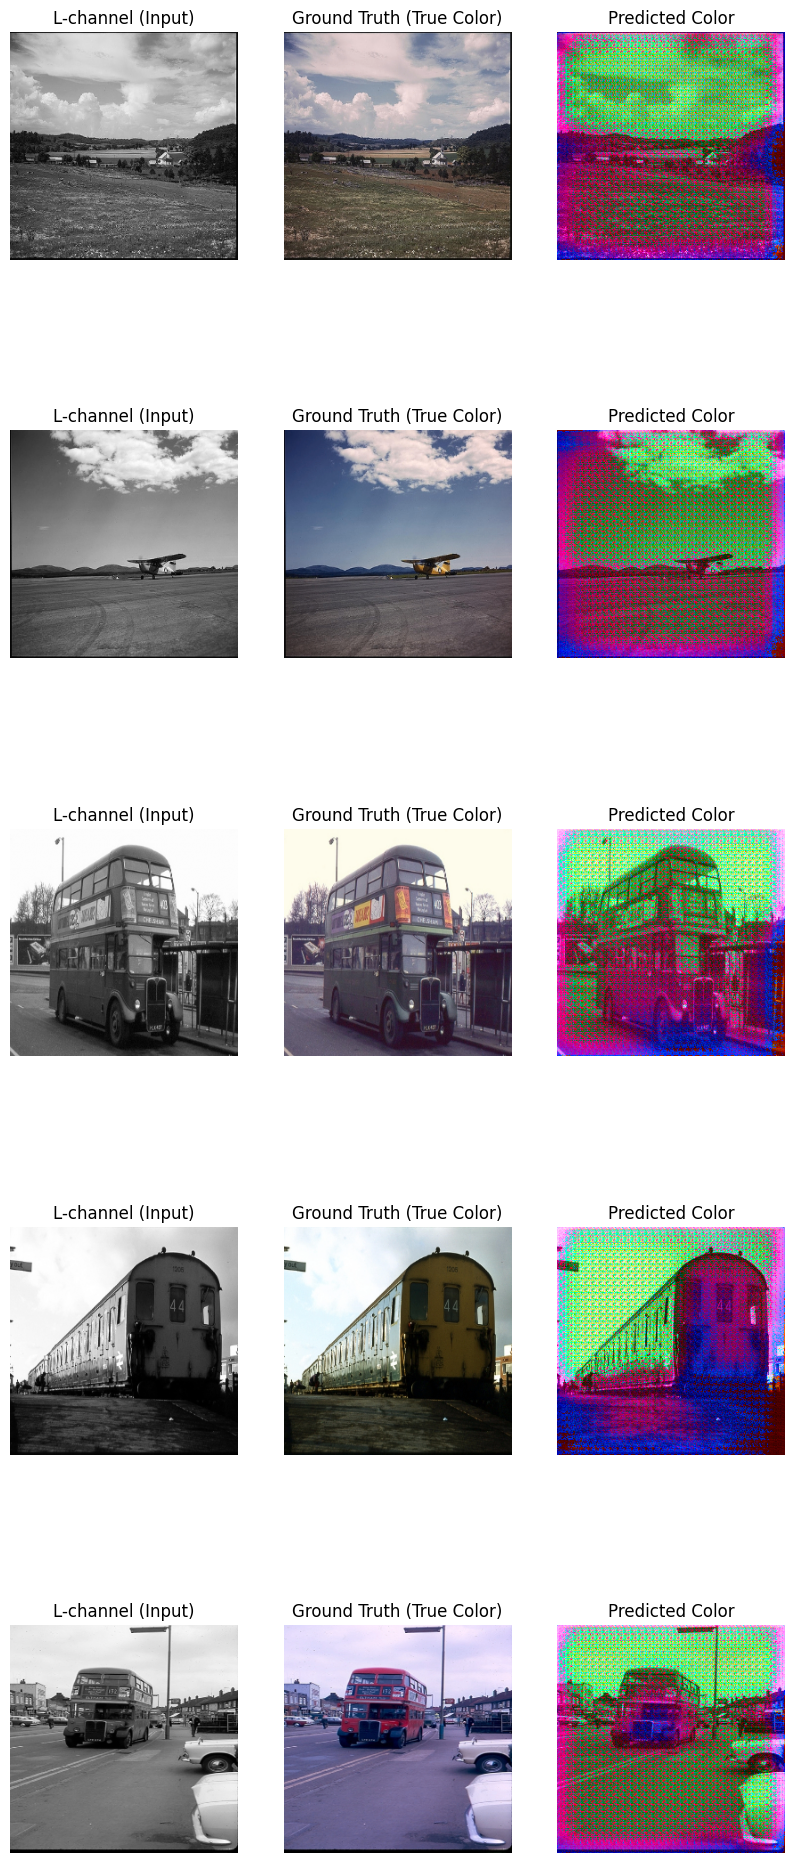

In [13]:
import numpy as np
import matplotlib.pyplot as plt
import cv2

def visualize_colorization(model, test_loader, num_images=5):
    model.eval()

    fig, axes = plt.subplots(num_images, 3, figsize=(10, 5 * num_images))

    with torch.no_grad():
        for i, (L, AB_true) in enumerate(test_loader):
            if i >= num_images:
                break  # Only visualize 'num_images' samples

            L, AB_true = L.to(device), AB_true.to(device)
            AB_pred = model(L)  # Predict AB channels

            # Convert tensors to NumPy arrays
            L = L.squeeze(1).cpu().numpy() * 255  # Shape (batch, 224, 224)
            AB_true = AB_true.cpu().numpy() * 128 + 128 # Shape (batch, 2, 224, 224)
            AB_pred = AB_pred.cpu().numpy() * 128 + 128 # Shape (batch, 2, 224, 224)

            for j in range(min(num_images, L.shape[0])):  # Iterate over batch samples
                true_lab = np.stack([L[j], AB_true[j, 0], AB_true[j, 1]], axis=-1).astype(np.uint8)
                pred_lab = np.stack([L[j], AB_pred[j, 0], AB_pred[j, 1]], axis=-1).astype(np.uint8)

                # Convert LAB to RGB
                true_rgb = cv2.cvtColor(true_lab, cv2.COLOR_LAB2RGB)
                pred_rgb = cv2.cvtColor(pred_lab, cv2.COLOR_LAB2RGB)

                # Plot results
                axes[j, 0].imshow(L[j], cmap="gray")
                axes[j, 0].set_title("L-channel (Input)")
                axes[j, 1].imshow(true_rgb)
                axes[j, 1].set_title("Ground Truth (True Color)")
                axes[j, 2].imshow(pred_rgb)
                axes[j, 2].set_title("Predicted Color")

                for ax in axes[j]:
                    ax.axis("off")

    plt.show()

# Call the function to visualize results
visualize_colorization(model, test_loader, num_images=5)


In [ ]:
torch.save(model.state_dict(), "colorization_model.pth")

In [14]:
# prompt: load the saved model

model = SmallECCVGenerator() #name of the specific model
model.load_state_dict(torch.load("colorization_model.pth"))
model.eval() # Set the model to evaluation mode


<ipython-input-14-0071b44ef097>:4: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load("colorization_model.pth"))


FileNotFoundError: [Errno 2] No such file or directory: 'colorization_model.pth'